# Лабораторная работа № 3. Градиентный спуск

**Вариант 17** (нечётный) — L2-регуляризация.

Цель работы:

1. Подготовить набор данных не менее чем с двумя признаками и обучить линейную регрессию своим градиентным спуском.
2. Проверить, как скорость обучения меняет сходимость.
3. Добавить выбор случайного объекта и получить стохастический градиентный спуск.
4. Сравнить среднеквадратичную ошибку обоих методов на одном графике.
5. Для 20 коэффициентов L2-регуляризации показать, как меняются веса.


## 1. Подготовка данных

Берётся синтетическая регрессия `sklearn.datasets.make_regression`: у неё известна линейная зависимость и заданный шум, поэтому по кривой ошибки видно именно поведение оптимизатора.

Условий задания здесь два. Признаков не меньше двух, а с учётом свободного члена весов не меньше трёх. В выборке 5 признаков, то есть 6 весов: так на графике регуляризации различимы отдельные траектории. `random_state=17` фиксирует вариант.

Признаки `make_regression` уже близки к стандартному нормальному закону, а целевая переменная имеет большой разброс из-за коэффициентов генерации. Без выравнивания масштабов один и тот же шаг $\alpha$ оказывается слишком крупным для части координат. Поэтому и $X$, и $y$ приводятся к нулевому среднему и единичной дисперсии (`StandardScaler`). Свободный член добавляется отдельно, уже после масштабирования: столбец единиц стандартизовать нельзя.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.unicode_minus": False,
    "font.size": 11,
})

FIG_DIR = Path(r"c:\Users\Егор\Desktop\sem7\mmo\mmo3\figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 17
N_SAMPLES = 300
N_FEATURES = 5

X, y, coef_true = make_regression(
    n_samples=N_SAMPLES,
    n_features=N_FEATURES,
    n_informative=N_FEATURES,
    noise=15.0,
    random_state=RANDOM_STATE,
    coef=True,
)

feature_names = [f"x{j}" for j in range(1, N_FEATURES + 1)]
raw = pd.DataFrame(X, columns=feature_names)
raw["y"] = y

print(f"Размерность: {raw.shape[0]} объектов, {N_FEATURES} признаков + целевая y")
print("Стандартные отклонения до масштабирования:")
print(raw.std(ddof=0).round(3).to_string())
print("\nКоэффициенты, которыми сгенерирована выборка:")
print(np.round(coef_true, 3))

scaler_x = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_x.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

print("\nПосле StandardScaler: среднее X =", np.round(X_scaled.mean(axis=0), 10))
print("После StandardScaler: std X =", np.round(X_scaled.std(axis=0), 10))
print(f"После StandardScaler: среднее y = {y_scaled.mean():.3e}, std y = {y_scaled.std():.3f}")


Размерность: 300 объектов, 5 признаков + целевая y
Стандартные отклонения до масштабирования:
x1      0.982
x2      1.046
x3      1.010
x4      1.013
x5      1.055
y     113.862

Коэффициенты, которыми сгенерирована выборка:
[28.608 57.745 25.62  16.294 77.397]

После StandardScaler: среднее X = [ 0.  0.  0. -0. -0.]
После StandardScaler: std X = [1. 1. 1. 1. 1.]
После StandardScaler: среднее y = 1.184e-17, std y = 1.000


## 2. Пакетный градиентный спуск

Модель со свободным членом:

$$h_w(x) = w_0 + w_1 x_1 + \ldots + w_n x_n, \quad x_0 = 1.$$

Минимизируется функция (множитель $\tfrac{1}{2}$ не сдвигает минимум и убирает двойку в производной):

$$J(w) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_w(x^{(i)}) - y^{(i)}\right)^2 + \frac{\lambda}{2}\sum_{j=1}^{n} w_j^2.$$

На графиках откладывается обычная среднеквадратичная ошибка, без коэффициента $\tfrac{1}{2}$:

$$\mathrm{MSE} = \frac{1}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)}) - y^{(i)}\right)^2.$$

В пунктах 2–5 штраф выключен: $\lambda = 0$. Член с $\lambda$ нужен в пункте 6. Свободный член $w_0$ не штрафуется.

Частная производная при $\lambda = 0$:

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)}) - y^{(i)}\right) x_j^{(i)}.$$

Алгоритм пакетного спуска:

1. Начальные веса — нули, задаётся порог $\varepsilon$.
2. Цикл ограничен числом итераций.
3. Новые веса: $w := w - \alpha \nabla J(w)$. В матричном виде градиент равен $\frac{1}{m} X^\top (Xw - y)$.
4. Цикл заканчивается, если $\|w^{(k+1)} - w^{(k)}\|_2 < \varepsilon$.

Параметр `stochastic` разбирается в пункте 4: при значении `False` градиент считается по всей выборке.


In [2]:
def gradient_descent(
    X,
    y,
    lr=0.1,
    n_iter=2000,
    eps=1e-6,
    reg=0.0,
    stochastic=False,
    random_state=17,
):
    # Линейная регрессия: пакетный или стохастический градиентный спуск.
    # reg — коэффициент L2. Свободный член не штрафуется.
    # stochastic=True — на каждой итерации берётся один случайный объект.
    # История — MSE по всей выборке после каждой итерации, включая старт.
    Xb = np.column_stack([np.ones(len(y)), np.asarray(X, dtype=float)])
    y = np.asarray(y, dtype=float)
    m, n_weights = Xb.shape
    w = np.zeros(n_weights)  # 1) начальные веса
    history = [float(np.mean((Xb @ w - y) ** 2))]
    rng = np.random.default_rng(random_state)

    for iteration in range(1, n_iter + 1):  # 2) цикл по итерациям
        if stochastic:
            # 4) один случайный объект вместо суммы по всей выборке
            idx = int(rng.integers(0, m))
            error_i = float(Xb[idx] @ w - y[idx])
            grad = error_i * Xb[idx]
        else:
            error = Xb @ w - y
            grad = (Xb.T @ error) / m

        # L2: к производной по w_j, j >= 1, добавляется λ w_j
        grad[1:] += reg * w[1:]

        # 3) новые веса
        w_new = w - lr * grad
        if not np.all(np.isfinite(w_new)):
            history.append(np.inf)
            return w, np.asarray(history, dtype=float), iteration

        delta = np.linalg.norm(w_new - w)
        w = w_new
        history.append(float(np.mean((Xb @ w - y) ** 2)))

        # 4) останов по малому изменению весов
        if eps > 0 and delta < eps:
            break

    return w, np.asarray(history, dtype=float), iteration


Xb = np.column_stack([np.ones(len(y_scaled)), X_scaled])
w_ls, *_ = np.linalg.lstsq(Xb, y_scaled, rcond=None)
mse_ls = float(np.mean((Xb @ w_ls - y_scaled) ** 2))

w_gd, hist_gd, iters_gd = gradient_descent(
    X_scaled, y_scaled, lr=0.1, n_iter=5000, eps=1e-8, reg=0.0, stochastic=False
)

linreg = LinearRegression().fit(X_scaled, y_scaled)
w_sklearn = np.r_[linreg.intercept_, linreg.coef_]

weight_names = [f"w{j}" for j in range(N_FEATURES + 1)]
compare = pd.DataFrame(
    {
        "Градиентный спуск": w_gd,
        "LinearRegression": w_sklearn,
        "МНК (lstsq)": w_ls,
    },
    index=weight_names,
)
print(f"Итераций до ||Δw|| < 1e-8: {iters_gd}")
print(f"MSE градиентного спуска: {hist_gd[-1]:.6f}")
print(f"MSE аналитического МНК:   {mse_ls:.6f}")
print(f"Макс. |w_gd - w_sklearn|: {np.max(np.abs(w_gd - w_sklearn)):.3e}")
print()
print(compare.round(6).to_string())


Итераций до ||Δw|| < 1e-8: 151
MSE градиентного спуска: 0.019140
MSE аналитического МНК:   0.019140
Макс. |w_gd - w_sklearn|: 5.647e-08

    Градиентный спуск  LinearRegression  МНК (lstsq)
w0           0.000000          0.000000    -0.000000
w1           0.236243          0.236243     0.236243
w2           0.537819          0.537819     0.537819
w3           0.220121          0.220121     0.220121
w4           0.138492          0.138492     0.138492
w5           0.720311          0.720311     0.720311


Веса пакетного спуска совпадают с `sklearn.linear_model.LinearRegression` и с аналитическим МНК. На стандартизованных данных свободный член равен нулю: и признаки, и целевая переменная центрированы. Минимальная MSE около 0,019 — это остаточный шум генерации, $R^2 \approx 0{,}981$.


## 3. Скорость обучения

Для нескольких значений $\alpha$ запускается тот же пакетный спуск из нулевых весов. Порог $\varepsilon$ здесь отключён, чтобы кривые имели общую длину и было видно поведение после выхода на минимум. Отдельно проверяется слишком большой шаг $\alpha = 2$.


 alpha  итераций до ε  итерация выхода на минимум  MSE на 200-й итерации  конечная MSE
  0.01           1332                         405               0.033412       0.01914
  0.10            151                          39               0.019140       0.01914
  0.50             27                           6               0.019140       0.01914
  1.00             10                           2               0.019140       0.01914
  1.50             50                           9               0.019140       0.01914

α = 2, MSE по итерациям (старт + 12 шагов):
[ 1.     1.226  1.518  1.898  2.395  3.051  3.924  5.103  6.718  8.965
 12.142 16.709 23.378]


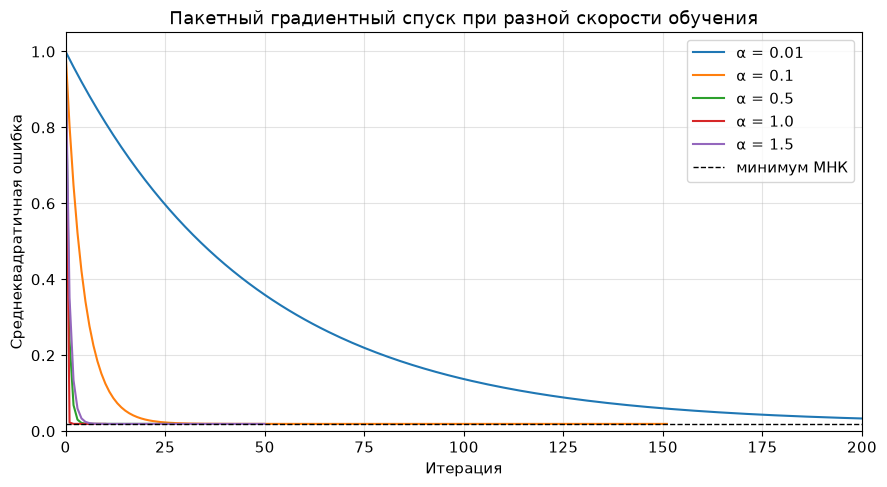

In [3]:
learning_rates = [0.01, 0.1, 0.5, 1.0, 1.5]
histories = {}
rows = []

for lr in learning_rates:
    w_lr, hist_lr, n_done = gradient_descent(
        X_scaled, y_scaled, lr=lr, n_iter=2000, eps=1e-8, stochastic=False
    )
    histories[lr] = hist_lr
    reached = np.where(hist_lr <= mse_ls * 1.01)[0]
    rows.append(
        {
            "alpha": lr,
            "итераций до ε": n_done,
            "итерация выхода на минимум": int(reached[0]) if len(reached) else None,
            "MSE на 200-й итерации": hist_lr[min(200, len(hist_lr) - 1)],
            "конечная MSE": hist_lr[-1],
        }
    )

summary_lr = pd.DataFrame(rows)
print(summary_lr.to_string(index=False))

# Слишком большой шаг: ошибка должна расти
_, hist_div, n_div = gradient_descent(
    X_scaled, y_scaled, lr=2.0, n_iter=12, eps=0.0, stochastic=False
)
print("\nα = 2, MSE по итерациям (старт + 12 шагов):")
print(np.round(hist_div, 3))

fig, ax = plt.subplots()
for lr, hist_lr in histories.items():
    ax.plot(np.arange(len(hist_lr)), hist_lr, label=f"α = {lr}")
ax.axhline(mse_ls, color="black", linestyle="--", linewidth=1, label="минимум МНК")
ax.set_xlim(0, 200)
ax.set_ylim(0, 1.05)
ax.set_xlabel("Итерация")
ax.set_ylabel("Среднеквадратичная ошибка")
ax.set_title("Пакетный градиентный спуск при разной скорости обучения")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_rate.png", dpi=150, bbox_inches="tight")
plt.show()


### Выводы по скорости обучения

Малый шаг $\alpha = 0{,}01$ сходится устойчиво, но медленно: к 200-й итерации ошибка ещё заметно выше минимума МНК, полный останов по $\varepsilon$ требует больше тысячи итераций.

Шаг $\alpha = 0{,}1$ выводит ошибку на минимум за несколько десятков итераций. При $\alpha = 0{,}5$ и $\alpha = 1$ это происходит ещё быстрее: после стандартизации кривизна $J(w)$ порядка единицы, и шаг около 1 близок к удобному для этого квадратичного функционала.

При $\alpha = 1{,}5$ метод всё ещё доходит до минимума, но останов по $\varepsilon$ наступает позже, чем при $\alpha = 1$: 50 итераций против 10. При $\alpha = 2$ ошибка растёт на каждой итерации, с 1 до 23 за 12 шагов: шаг перешагивает минимум, и процесс расходится.

Дальше для пакетного спуска берётся $\alpha = 0{,}1$: запас до границы расходимости остаётся, а минимум достигается быстро.


## 4. Стохастический градиентный спуск

В ту же функцию добавлен выбор одного случайного объекта на каждой итерации (`stochastic=True`).

Индекс $i$ берётся равновероятно из $\{0,\ldots,m-1\}$, и шаг идёт по градиенту только этого объекта:

$$w := w - \alpha \left(h_w(x^{(i)}) - y^{(i)}\right) x^{(i)}.$$

Это несмещённая оценка полного градиента: среднее однообъектных градиентов совпадает с $\frac{1}{m} X^\top (Xw - y)$. Дисперсия оценки больше, чем у полного градиента, поэтому устойчивый шаг меньше. Подходящее $\alpha$ выбирается по нескольким запускам.

Критерий $\|w^{(k+1)} - w^{(k)}\| < \varepsilon$ для стохастического режима слабый: даже рядом с минимумом шаг по случайному объекту не становится нулевым. Поэтому сравнение в пункте 5 идёт по фиксированному числу итераций, а в истории по-прежнему записывается MSE на всей выборке. Так кривые двух методов стоят в одной шкале. Сам шаг стохастического спуска всю выборку не читает.


In [4]:
sgd_rates = [0.001, 0.01, 0.05, 0.1]
sgd_rows = []
for lr in sgd_rates:
    _, hist_try, n_try = gradient_descent(
        X_scaled,
        y_scaled,
        lr=lr,
        n_iter=1500,
        eps=0.0,
        stochastic=True,
        random_state=RANDOM_STATE,
    )
    sgd_rows.append(
        {
            "alpha": lr,
            "MSE на последней итерации": hist_try[-1],
            "средняя MSE последних 100 итераций": hist_try[-100:].mean(),
            "минимум MSE по траектории": hist_try.min(),
        }
    )

print(pd.DataFrame(sgd_rows).to_string(index=False))
print(f"\nОриентир — MSE аналитического МНК: {mse_ls:.6f}")


 alpha  MSE на последней итерации  средняя MSE последних 100 итераций  минимум MSE по траектории
 0.001                   0.068467                            0.075110                   0.068467
 0.010                   0.019496                            0.019492                   0.019160
 0.050                   0.022775                            0.021100                   0.019201
 0.100                   0.033591                            0.025483                   0.019583

Ориентир — MSE аналитического МНК: 0.019140


При $\alpha = 0{,}001$ за 1500 итераций MSE снижается только до 0,068 и до минимума МНК (0,019) не доходит. При $\alpha = 0{,}01$ средняя ошибка последних 100 итераций равна 0,0195 и уже лежит рядом с МНК. При $\alpha = 0{,}05$ и $\alpha = 0{,}1$ хвост траектории остаётся выше: около 0,021 и 0,025. Для сравнения методов берётся $\alpha = 0{,}01$.


## 5. Сравнение пакетного и стохастического спуска

Обе модели стартуют из нулевых весов. Пакетный спуск идёт с $\alpha = 0{,}1$, стохастический — с $\alpha = 0{,}01$. На графике одна величина: MSE по всем 300 объектам. Для стохастической кривой дополнительно проведено скользящее среднее по 30 итерациям, чтобы на фоне шума был виден тренд.


Веса обученных моделей:
    Пакетный  Стохастический  LinearRegression
w0   0.00000         0.00388           0.00000
w1   0.23624         0.24830           0.23624
w2   0.53782         0.54642           0.53782
w3   0.22012         0.21820           0.22012
w4   0.13849         0.12629           0.13849
w5   0.72031         0.73392           0.72031

Пакетный:        итераций в запуске = 151, конечная MSE = 0.019140
Стохастический:  итераций в запуске = 1000, конечная MSE = 0.019720
Итерация, на которой MSE впервые ≤ 0.02010 (на 5 % выше МНК):
  пакетный — 32
  стохастический — 347
Оценка числа просмотренных объектов до этого момента: пакетный 9600, стохастический 347.


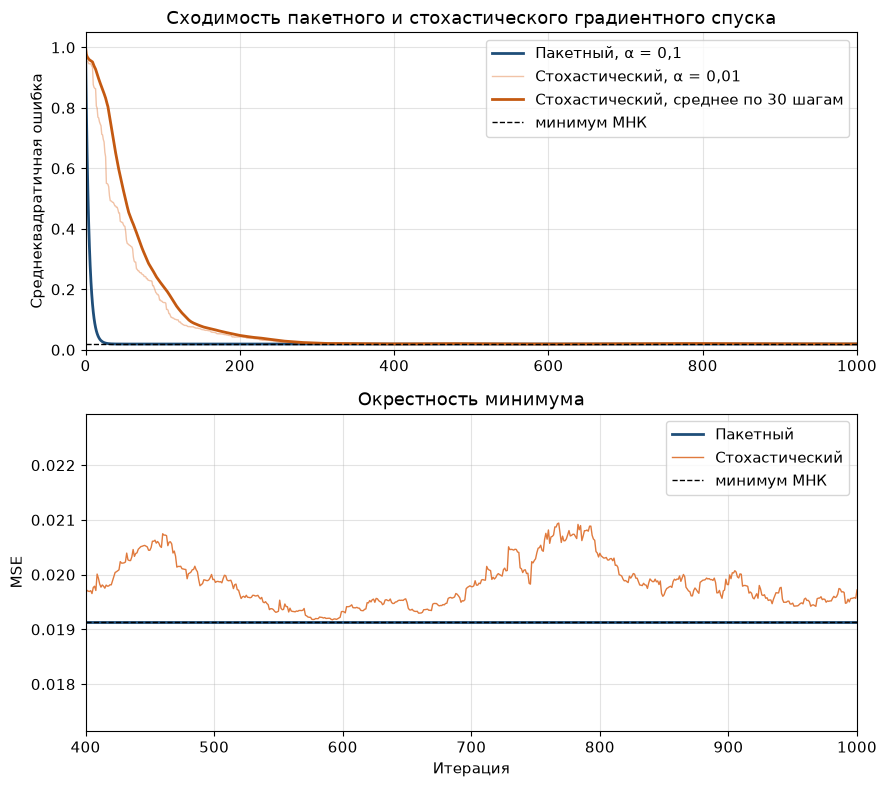

In [5]:
N_COMPARE = 1000

w_batch, hist_batch, iters_batch = gradient_descent(
    X_scaled,
    y_scaled,
    lr=0.1,
    n_iter=N_COMPARE,
    eps=1e-8,
    stochastic=False,
)
w_stoch, hist_stoch, iters_stoch = gradient_descent(
    X_scaled,
    y_scaled,
    lr=0.01,
    n_iter=N_COMPARE,
    eps=0.0,
    stochastic=True,
    random_state=RANDOM_STATE,
)

threshold = mse_ls * 1.05
batch_hit = int(np.where(hist_batch <= threshold)[0][0])
stoch_hit = int(np.where(hist_stoch <= threshold)[0][0])

weights = pd.DataFrame(
    {
        "Пакетный": w_batch,
        "Стохастический": w_stoch,
        "LinearRegression": w_sklearn,
    },
    index=weight_names,
)
print("Веса обученных моделей:")
print(weights.round(5).to_string())
print()
print(f"Пакетный:        итераций в запуске = {iters_batch}, конечная MSE = {hist_batch[-1]:.6f}")
print(f"Стохастический:  итераций в запуске = {iters_stoch}, конечная MSE = {hist_stoch[-1]:.6f}")
print(f"Итерация, на которой MSE впервые ≤ {threshold:.5f} (на 5 % выше МНК):")
print(f"  пакетный — {batch_hit}")
print(f"  стохастический — {stoch_hit}")
print(
    "Оценка числа просмотренных объектов до этого момента: "
    f"пакетный {batch_hit * N_SAMPLES}, стохастический {stoch_hit}."
)

def hold_last(hist, length):
    hist = np.asarray(hist, dtype=float)
    if len(hist) >= length:
        return hist[:length]
    # После останова по ε веса не меняются, поэтому MSE остаётся на достигнутом уровне.
    return np.pad(hist, (0, length - len(hist)), constant_values=hist[-1])

curve_len = N_COMPARE + 1
batch_curve = hold_last(hist_batch, curve_len)
stoch_curve = hold_last(hist_stoch, curve_len)
roll = pd.Series(stoch_curve).rolling(30, min_periods=1).mean()

fig, axes = plt.subplots(2, 1, figsize=(9, 8))
axes[0].plot(batch_curve, color="#1f4e79", linewidth=2, label="Пакетный, α = 0,1")
axes[0].plot(stoch_curve, color="#e07a3d", alpha=0.45, linewidth=1, label="Стохастический, α = 0,01")
axes[0].plot(roll, color="#c45911", linewidth=2, label="Стохастический, среднее по 30 шагам")
axes[0].axhline(mse_ls, color="black", linestyle="--", linewidth=1, label="минимум МНК")
axes[0].set_xlim(0, N_COMPARE)
axes[0].set_ylim(0, 1.05)
axes[0].set_ylabel("Среднеквадратичная ошибка")
axes[0].set_title("Сходимость пакетного и стохастического градиентного спуска")
axes[0].legend()

zoom_from = 400
tail = stoch_curve[zoom_from:]
pad = max(0.002, 0.25 * (tail.max() - mse_ls))
axes[1].plot(np.arange(zoom_from, curve_len), batch_curve[zoom_from:], color="#1f4e79", linewidth=2, label="Пакетный")
axes[1].plot(np.arange(zoom_from, curve_len), stoch_curve[zoom_from:], color="#e07a3d", linewidth=1, label="Стохастический")
axes[1].axhline(mse_ls, color="black", linestyle="--", linewidth=1, label="минимум МНК")
axes[1].set_xlim(zoom_from, N_COMPARE)
axes[1].set_ylim(mse_ls - pad, float(tail.max()) + pad)
axes[1].set_xlabel("Итерация")
axes[1].set_ylabel("MSE")
axes[1].set_title("Окрестность минимума")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "gd_vs_sgd.png", dpi=150, bbox_inches="tight")
plt.show()


### Выводы по сходимости

Пакетный спуск даёт гладкую кривую. Уровень «MSE не более чем на 5 % выше МНК» достигается на 32-й итерации, а останов по $\varepsilon$ — на 151-й. Конечная ошибка совпадает с МНК: 0,019140.

Стохастический спуск добирается до того же порога на 347-й итерации. На увеличенном фрагменте видно, что дальше кривая не замирает, а колеблется вокруг минимума: после 1000 шагов MSE равна 0,01972, а веса близки к `LinearRegression`, но не совпадают с ним.

По числу итераций быстрее пакетный метод. По объёму данных быстрее стохастический: один его шаг читает один объект, а один шаг пакетного метода — все 300. До указанного порога это 347 объектов против $32 \times 300 = 9600$, то есть примерно в 28 раз больше просмотров строк. На этой выборке оба метода выходят на ошибку около 0,019; выигрыш стохастического спуска — цена итерации, а не более низкая ошибка.


## 6. L2-регуляризация

Вариант 17 нечётный, поэтому к функции потерь добавляется L2-штраф. Свободный член по-прежнему не регуляризуется:

$$\frac{\partial J}{\partial w_0} = \frac{1}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)}) - y^{(i)}\right),$$

$$\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}\left(h_w(x^{(i)}) - y^{(i)}\right) x_j^{(i)} + \lambda w_j, \quad j \ge 1.$$

Берутся 20 коэффициентов на логарифмической сетке от 0,001 до 1000. Для каждого $\lambda$ веса считаются пакетным спуском. Шаг уменьшается вместе с ростом $\lambda$, иначе штрафной член $\lambda w$ делает обновление расходящимся:

$$\alpha(\lambda) = \min\left(0{,}3,\ \frac{0{,}5}{1+\lambda}\right).$$

Проверка: стационарная точка этого градиента совпадает с `sklearn.linear_model.Ridge` при `alpha = m·λ`, где $m = 300$.


Сверка с sklearn.Ridge (alpha = m·λ):
  lambda  max |w - Ridge|
   0.001     1.306228e-10
   1.000     5.304607e-11
 100.000     5.496813e-11
1000.000     4.494208e-11

Веса и MSE вдоль сетки λ:
    lambda  w0      w1      w2      w3      w4      w5     MSE  итераций
   0.00100 0.0 0.23600 0.53732 0.21993 0.13835 0.71962 0.01914        63
   0.00207 0.0 0.23575 0.53678 0.21972 0.13819 0.71889 0.01914        63
   0.00428 0.0 0.23522 0.53568 0.21929 0.13787 0.71738 0.01916        63
   0.00886 0.0 0.23413 0.53341 0.21841 0.13721 0.71427 0.01921        62
   0.01833 0.0 0.23192 0.52877 0.21661 0.13587 0.70792 0.01943        62
   0.03793 0.0 0.22747 0.51942 0.21298 0.13317 0.69513 0.02033        60
   0.07848 0.0 0.21878 0.50109 0.20583 0.12791 0.67010 0.02386        57
   0.16238 0.0 0.20277 0.46697 0.19247 0.11824 0.62363 0.03666        52
   0.33598 0.0 0.17611 0.40929 0.16967 0.10223 0.54540 0.07655        44
   0.69519 0.0 0.13846 0.32593 0.13626 0.07984 0.43304 0.17424        32
  

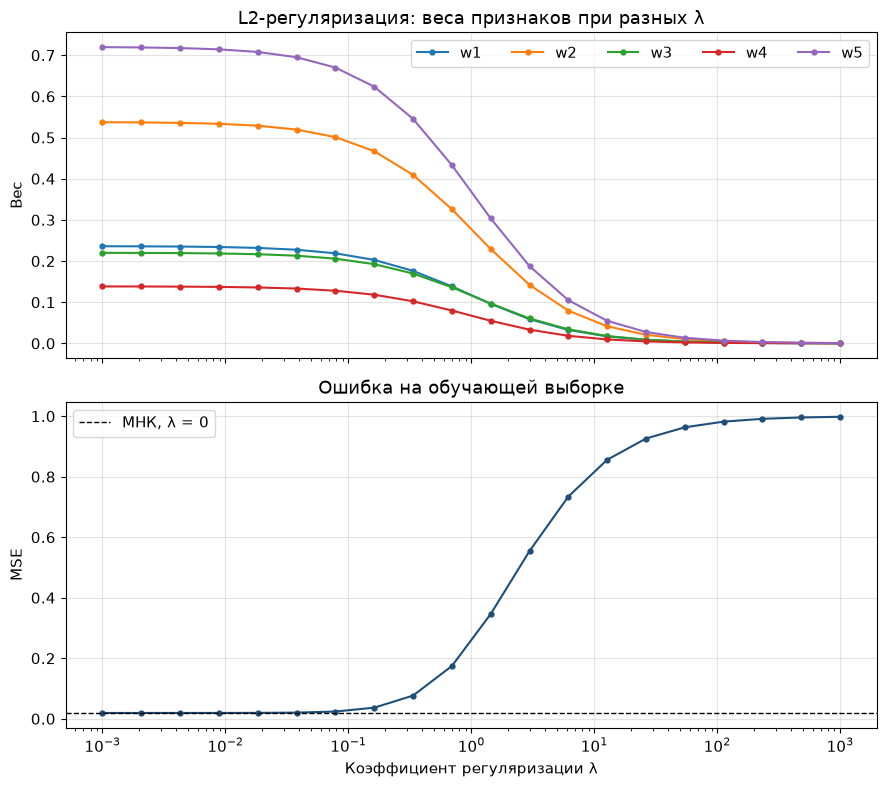

max |w_j| при λ = 0.001: 0.71962
max |w_j| при λ = 1000: 0.00075
w0 на всей сетке лежит в [1.735e-19; 1.596e-17]


In [6]:
lambdas = np.logspace(-3, 3, 20)
path = []
path_mse = []
path_iters = []

for lam in lambdas:
    lr_lam = min(0.3, 0.5 / (1.0 + lam))
    w_lam, hist_lam, n_lam = gradient_descent(
        X_scaled,
        y_scaled,
        lr=lr_lam,
        n_iter=5000,
        eps=1e-10,
        reg=float(lam),
        stochastic=False,
    )
    path.append(w_lam)
    path_mse.append(hist_lam[-1])
    path_iters.append(n_lam)

path = np.vstack(path)
path_mse = np.asarray(path_mse)

check_rows = []
for lam in (0.001, 1.0, 100.0, 1000.0):
    lr_lam = min(0.3, 0.5 / (1.0 + lam))
    w_lam, _, _ = gradient_descent(
        X_scaled,
        y_scaled,
        lr=lr_lam,
        n_iter=5000,
        eps=1e-10,
        reg=float(lam),
        stochastic=False,
    )
    ridge = Ridge(alpha=N_SAMPLES * lam, fit_intercept=True).fit(X_scaled, y_scaled)
    w_ridge = np.r_[ridge.intercept_, ridge.coef_]
    check_rows.append(
        {
            "lambda": lam,
            "max |w - Ridge|": np.max(np.abs(w_lam - w_ridge)),
        }
    )

print("Сверка с sklearn.Ridge (alpha = m·λ):")
print(pd.DataFrame(check_rows).to_string(index=False))

table = pd.DataFrame(path, columns=weight_names)
table.insert(0, "lambda", lambdas)
table["MSE"] = path_mse
table["итераций"] = path_iters
print("\nВеса и MSE вдоль сетки λ:")
print(table.round(5).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

for j, name in enumerate(weight_names[1:], start=1):
    axes[0].plot(lambdas, path[:, j], marker="o", markersize=3.5, label=name)
axes[0].set_ylabel("Вес")
axes[0].set_title("L2-регуляризация: веса признаков при разных λ")
axes[0].legend(ncol=5)

axes[1].plot(lambdas, path_mse, color="#1f4e79", marker="o", markersize=3.5)
axes[1].axhline(mse_ls, color="black", linestyle="--", linewidth=1, label="МНК, λ = 0")
axes[1].set_xscale("log")
axes[1].set_xlabel("Коэффициент регуляризации λ")
axes[1].set_ylabel("MSE")
axes[1].set_title("Ошибка на обучающей выборке")
axes[1].legend()

fig.tight_layout()
fig.savefig(FIG_DIR / "l2_weights.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"max |w_j| при λ = {lambdas[0]:.3g}: {np.max(np.abs(path[0, 1:])):.5f}")
print(f"max |w_j| при λ = {lambdas[-1]:.0f}: {np.max(np.abs(path[-1, 1:])):.5f}")
print(f"w0 на всей сетке лежит в [{path[:, 0].min():.3e}; {path[:, 0].max():.3e}]")


### Выводы по L2-регуляризации

На широкой сетке от 0,001 до 1000 веса признаков монотонно стягиваются к нулю. При $\lambda = 0{,}001$ они практически совпадают с МНК, MSE остаётся около 0,019. К $\lambda = 1000$ все штрафные веса по модулю меньше $10^{-3}$, а MSE поднимается почти до 1 — до ошибки константного прогноза на стандартизованной целевой переменной.

Свободный член на всей сетке остаётся около нуля: данные центрированы, и $w_0$ в штраф не входит.

Слишком большой $\lambda$ упрощает модель до константы и перестаёт объяснять $y$. Малый $\lambda$ почти не отличается от обычного МНК. Рабочий диапазон на этих данных — промежуточные значения, где норма весов уже меньше, а рост MSE ещё умеренный. Сверка с `Ridge` подтверждает, что стационарная точка реализованного градиента совпадает с библиотечной L2-регрессией.


## Выводы

1. На выборке из 300 объектов и 5 признаков (6 весов вместе со свободным членом) пакетный градиентный спуск из нулевых весов приходит к тому же решению, что `LinearRegression` и аналитический МНК. Масштабирование нужно из-за большого разброса $y$.
2. Скорость обучения определяет режим. $\alpha = 0{,}01$ сходится медленно, $\alpha = 0{,}1$–$1$ — быстро и устойчиво, $\alpha = 2$ приводит к росту ошибки на каждом шаге.
3. Стохастический вариант — та же функция с выбором одного случайного объекта. Его кривая MSE шумная и по числу итераций отстаёт от пакетного спуска, зато каждый шаг дешевле в $m$ раз. Оба метода выходят на ошибку около 0,019; пакетный останавливается в минимуме, стохастический колеблется вокруг него.
4. Для нечётного варианта 17 включена L2-регуляризация. На 20 коэффициентах от 0,001 до 1000 веса признаков убывают к нулю, а обучающая MSE растёт от уровня МНК до ошибки константы. Свободный член не штрафуется и не меняется.
